## <b>Data Preprocessing

### 1 Dataset Loading and Data Analysis

Load the OCTMNIST dataset at 64×64 resolution and inspect its structure, including image dimensions, class labels, and dataset sizes. Visualize representative images to understand the dataset.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from medmnist import INFO

dataset_path = Path("../data/octmnist_64.npz")
data = np.load(dataset_path)

# Dataset metadata
info = INFO["octmnist"]
class_names = list(info["label"].values())
class_ids = list(info["label"].keys())

print("===== OCTMNIST Dataset Summary =====")
print(f"Number of classes : {len(class_names)}")
print(f"Class names       : {', '.join(class_names)}")

total = 0

print("Available keys:", data.files)

for split in ["train", "val", "test"]:
    images = data[f"{split}_images"]
    labels = data[f"{split}_labels"].flatten()
    total += len(images)

    print(f"\n{split.upper()} SET")
    print(f"Number of images : {len(images):,}")
    print(f"Image shape      : {images.shape[1:]}")
    print(f"Class counts     :")

    counts = np.bincount(labels, minlength=len(class_names))
    for name, count in zip(class_names, counts):
        print(f"  {name:<8}: {count:,}")

print(f"\nTotal images     : {total:,}")

===== OCTMNIST Dataset Summary =====
Number of classes : 4
Class names       : choroidal neovascularization, diabetic macular edema, drusen, normal
Available keys: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']

TRAIN SET
Number of images : 97,477
Image shape      : (64, 64)
Class counts     :
  choroidal neovascularization: 33,484
  diabetic macular edema: 10,213
  drusen  : 7,754
  normal  : 46,026

VAL SET
Number of images : 10,832
Image shape      : (64, 64)
Class counts     :
  choroidal neovascularization: 3,721
  diabetic macular edema: 1,135
  drusen  : 862
  normal  : 5,114

TEST SET
Number of images : 1,000
Image shape      : (64, 64)
Class counts     :
  choroidal neovascularization: 250
  diabetic macular edema: 250
  drusen  : 250
  normal  : 250

Total images     : 109,309


### 2 Image Resolution Downscaling

The OCTMNIST dataset was downloaded at 64×64 pixel resolution, satisfying the assignment's maximum image resolution requirement. Therefore, no additional downscaling was necessary.

### 3 Dataset Splitting

Combine the original dataset subsets and perform a stratified 70:15:15 split for training, validation, and testing, as required by the assignment. Verify the splitting ratios and class distributions.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

X_all = np.concatenate([
    data["train_images"],
    data["val_images"],
    data["test_images"]
], axis=0)

y_all = np.concatenate([
    data["train_labels"],
    data["val_labels"],
    data["test_labels"]
], axis=0).flatten()

# Keep track of the original partition for each image
original_split = np.concatenate([
    np.full(len(data["train_images"]), "train"),
    np.full(len(data["val_images"]), "val"),
    np.full(len(data["test_images"]), "test")
])

# Unique positional index for every source image
all_indices = np.arange(len(y_all))

print("All images:", X_all.shape)
print("All labels:", y_all.shape)
print("All indices:", all_indices.shape)

All images: (109309, 64, 64)
All labels: (109309,)
All indices: (109309,)


In [4]:
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42,
    stratify=y_all
)

print("Training indices:", train_idx.shape)
print("Remaining indices:", temp_idx.shape)

Training indices: (76516,)
Remaining indices: (32793,)


In [5]:
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y_all[temp_idx]
)

# Construct image and label partitions
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (76516, 64, 64)
Validation: (16396, 64, 64)
Testing: (16397, 64, 64)


Verify the splitting ratios and class distributions.

In [6]:
for split_name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    counts = np.bincount(labels.flatten(), minlength=len(class_ids))

    print(f"\n{split_name} Set: ({len(labels)/total*100:.2f}%)")

    for class_id in class_ids:
        name = info["label"][class_id]
        count = counts[int(class_id)]
        print(f"  {class_id} {name}: {count}")



Training Set: (70.00%)
  0 choroidal neovascularization: 26218
  1 diabetic macular edema: 8119
  2 drusen: 6206
  3 normal: 35973

Validation Set: (15.00%)
  0 choroidal neovascularization: 5618
  1 diabetic macular edema: 1740
  2 drusen: 1330
  3 normal: 7708

Testing Set: (15.00%)
  0 choroidal neovascularization: 5619
  1 diabetic macular edema: 1739
  2 drusen: 1330
  3 normal: 7709


### 4 Dataset Integrity and Leakage Checks

Verify that the data partitions have no shared source-image
indices and investigate exact duplicate images across splits.

In [7]:
import hashlib
from collections import defaultdict

# 1. Check positional-index overlap
train_set = set(train_idx)
val_set = set(val_idx)
test_set = set(test_idx)

print("===== SPLIT INTEGRITY =====")

print("Train / Validation overlap:",
      len(train_set & val_set))

print("Train / Test overlap:",
      len(train_set & test_set))

print("Validation / Test overlap:",
      len(val_set & test_set))

assert len(train_set & val_set) == 0
assert len(train_set & test_set) == 0
assert len(val_set & test_set) == 0

assert len(train_set | val_set | test_set) == len(X_all)

print("Index integrity: PASSED")


# 2. Detect exact duplicate image content
def image_hash(image):
    return hashlib.sha256(
        np.ascontiguousarray(image).tobytes()
    ).hexdigest()


hash_locations = defaultdict(set)
hash_counts = defaultdict(lambda: defaultdict(int))
hash_labels = defaultdict(set)

partitions = [
    ("train", train_idx),
    ("val", val_idx),
    ("test", test_idx)
]

for split_name, indices in partitions:
    for idx in indices:
        h = image_hash(X_all[idx])

        hash_locations[h].add(split_name)
        hash_counts[h][split_name] += 1
        hash_labels[h].add(int(y_all[idx]))

duplicate_hashes = [
    h for h, locations in hash_locations.items()
    if len(locations) > 1
]

print("\n===== EXACT DUPLICATE CHECK =====")
print("Unique image hashes:", len(hash_locations))

print("Hashes shared across splits:",
      len(duplicate_hashes))

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    shared = sum(
        1 for h in hash_locations
        if a in hash_locations[h] and b in hash_locations[h]
    )

    print(f"{a} / {b} shared hashes: {shared}")

conflicting_labels = sum(
    len(labels) > 1
    for labels in hash_labels.values()
)

print("Hashes with conflicting labels:",
      conflicting_labels)

for split_name in ["train", "val", "test"]:
    affected = sum(
        hash_counts[h][split_name]
        for h in duplicate_hashes
    )
    print(f"{split_name} images sharing content "
          f"with another split: {affected}")

===== SPLIT INTEGRITY =====
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0
Index integrity: PASSED

===== EXACT DUPLICATE CHECK =====
Unique image hashes: 101418
Hashes shared across splits: 3485
train / val shared hashes: 1631
train / test shared hashes: 1614
val / test shared hashes: 364
Hashes with conflicting labels: 269
train images sharing content with another split: 3554
val images sharing content with another split: 1980
test images sharing content with another split: 1969


In [8]:
# Save split indices for reproducibility
split_path = Path("../data/split_indices_seed42.npz")

np.savez_compressed(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Saved split indices to:", split_path)

Saved split indices to: ..\data\split_indices_seed42.npz


## 5. Image Normalization and CNN Input Preparation

In [9]:
# Check the original data
print("Original shape:", X_train.shape)
print("Original dtype:", X_train.dtype)
print("Original range:", X_train.min(), X_train.max())

# Normalize images to [0, 1] and add channel dimension
# float32 conversion happens during batch loading to save RAM

def preprocess_images(images):
    images = images.astype(np.float32) / 255.0
    images = np.expand_dims(images, axis=-1)
    return images

# Test preprocessing with a small batch
sample_batch = preprocess_images(X_train[:32])

print("\nProcessed batch shape:", sample_batch.shape)
print("Processed dtype:", sample_batch.dtype)
print("Processed range:", sample_batch.min(), sample_batch.max())

Original shape: (76516, 64, 64)
Original dtype: uint8
Original range: 0 255

Processed batch shape: (32, 64, 64, 1)
Processed dtype: float32
Processed range: 0.003921569 1.0


In [10]:
assert sample_batch.ndim == 4
assert sample_batch.shape[1:] == (64, 64, 1)
assert sample_batch.dtype == np.float32

assert sample_batch.min() >= 0.0
assert sample_batch.max() <= 1.0

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert np.all((y_all >= 0) & (y_all < 4))

print("CNN input preprocessing verified successfully!")

CNN input preprocessing verified successfully!


## 6. Dataset Visualization
Visualize representative OCT images from each class using
the training partition only.

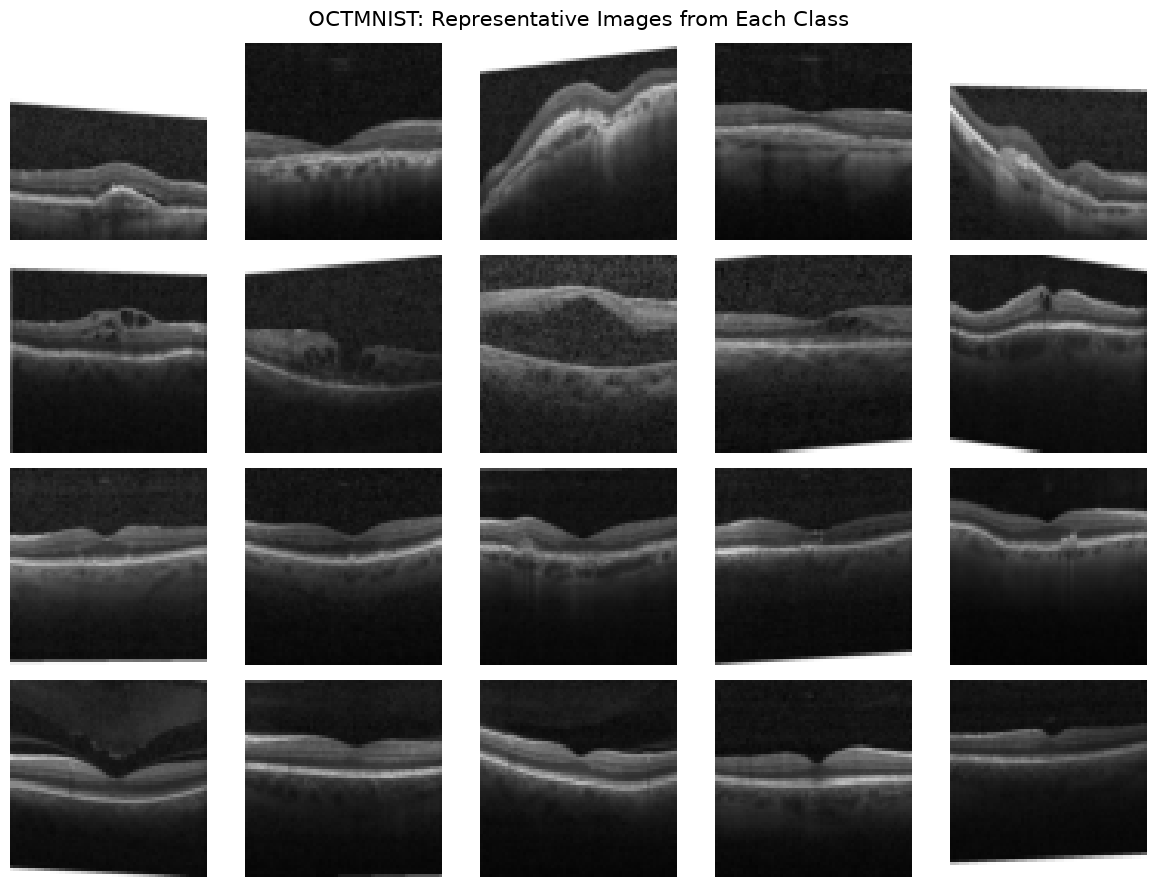

In [11]:
import matplotlib.pyplot as plt
import numpy as np

class_names = {
    0: "CNV",
    1: "DME",
    2: "Drusen",
    3: "Normal"
}

samples_per_class = 5
rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    4, samples_per_class,
    figsize=(12, 9)
)

for class_id, class_name in class_names.items():

    # Find images belonging to this class
    class_indices = np.where(y_train == class_id)[0]

    # Randomly select representative samples
    selected_indices = rng.choice(
        class_indices,
        size=samples_per_class,
        replace=False
    )

    for col, idx in enumerate(selected_indices):

        ax = axes[class_id, col]

        ax.imshow(
            X_train[idx],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        ax.axis("off")

        if col == 0:
            ax.set_ylabel(
                class_name,
                fontsize=12,
                rotation=90,
                labelpad=12
            )
            ax.yaxis.set_label_position("left")

fig.suptitle(
    "OCTMNIST: Representative Images from Each Class",
    fontsize=15
)

plt.tight_layout()

# Save for the assignment report
plt.savefig(
    "../data/octmnist_samples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 7. TensorFlow Data Pipeline
Prepare batched, normalized datasets for CNN training.

In [12]:
import tensorflow as tf
import numpy as np

SEED = 42
BATCH_SIZE = 32
NUM_CLASSES = 4

tf.random.set_seed(SEED)

def make_dataset(images, labels, training=False):
    # Read images from existing NumPy arrays
    def generator():
        for image, label in zip(images, labels):
            yield image, np.int32(label)

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(64, 64), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )

    if training:
        ds = ds.shuffle(
            buffer_size=2048,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)

    def preprocess(image, label):
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.expand_dims(image, axis=-1)
        return image, label

    ds = ds.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.prefetch(1)


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

    assert images.shape == (32, 64, 64, 1)
    assert labels.shape == (32,)
    assert images.dtype == tf.float32
    assert labels.dtype == tf.int32
    assert tf.reduce_min(images) >= 0
    assert tf.reduce_max(images) <= 1

print("Data pipeline verification PASSED!")

Image batch shape: (32, 64, 64, 1)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Pixel range: 0.0 1.0
Data pipeline verification PASSED!
